# 03 - Analyse exploratoire & Réponses aux questions métier

Ce notebook exploite les données consolidées (`data/processed/cleaned_salaries.csv`).
Les 5 visualisations générées sont exportées dans le dossier `figures/`.

In [1]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

path_processed = os.path.join("..", "data", "processed")
path_figures = os.path.join("..", "figures")
os.makedirs(path_figures, exist_ok=True)

df = pd.read_csv(os.path.join(path_processed, "cleaned_salaries.csv"))
print(f"Lignes : {df.shape[0]}, Colonnes : {df.shape[1]}")

Lignes : 5341, Colonnes : 18


## Question 1 : Écart salarial entre profils IA / ML et Data Analytics selon la séniorité

Salaires médians en USD :
experience_level_fr    Intermédiaire   Junior  Lead / Exec    Senior
job_group                                                           
Autre Data                  110000.0  76833.0     200000.0  150000.0
Data Analytics               93000.0  61360.0     151500.0  127075.0
Data Engineering            104584.0  80000.0     185000.0  149538.0
Data Science                116914.0  90000.0     192500.0  168200.0
IA & Machine Learning       130000.0  66192.0     200000.0  184975.0


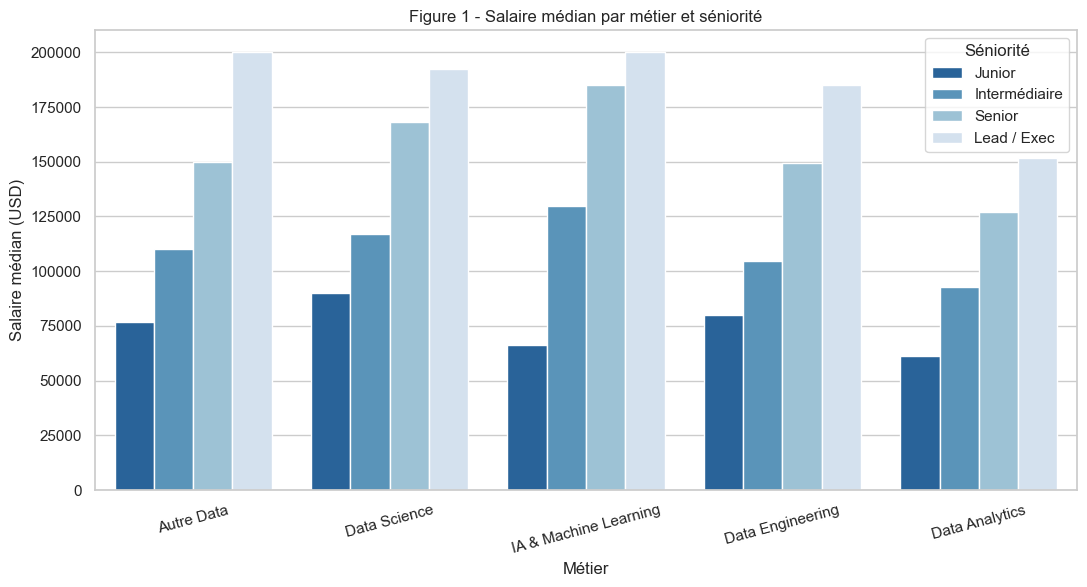

In [2]:
q1_pivot = (
    df.groupby(["job_group", "experience_level_fr"])["salary_in_usd"]
    .median()
    .unstack()
)
print("Salaires médians en USD :")
print(q1_pivot.round(0))

plt.figure(figsize=(11, 6))
order_exp = ["Junior", "Intermédiaire", "Senior", "Lead / Exec"]
sns.barplot(
    data=df,
    x="job_group",
    y="salary_in_usd",
    hue="experience_level_fr",
    hue_order=order_exp,
    estimator="median",
    errorbar=None,
    palette="Blues_r",
)
plt.title("Figure 1 - Salaire médian par métier et séniorité")
plt.xlabel("Métier")
plt.ylabel("Salaire médian (USD)")
plt.legend(title="Séniorité")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(os.path.join(path_figures, "fig1_salaires_metiers_experience.png"))
plt.show()

**Conclusion Question 1 :**  
Les profils IA & Machine Learning enregistrent les rémunérations médianes les plus élevées à tous les échelons, avec un gap dépassant 30 000 $ annuels face aux Data Analysts aux niveaux Senior et Lead.

## Question 2 : Impact du télétravail sur les rémunérations

              count    median      mean
work_setting                           
Hybrid          189   74000.0   89109.0
In-person      2913  145000.0  153629.0
Remote         2239  137141.0  141493.0


/var/folders/8_/0gftngvx6hv1b_1p1qtpmt240000gn/T/ipykernel_14831/376062728.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


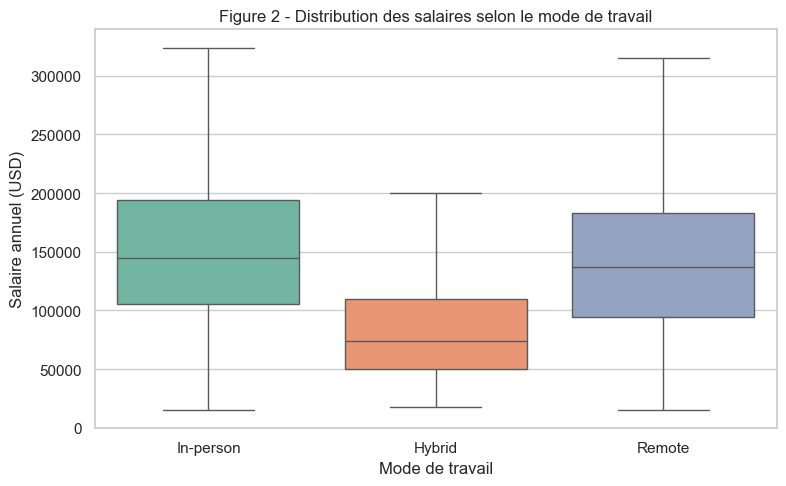

In [3]:
print(
    df.groupby("work_setting")["salary_in_usd"]
    .agg(["count", "median", "mean"])
    .round(0)
)

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="work_setting",
    y="salary_in_usd",
    order=["In-person", "Hybrid", "Remote"],
    palette="Set2",
    showfliers=False,
)
plt.title("Figure 2 - Distribution des salaires selon le mode de travail")
plt.xlabel("Mode de travail")
plt.ylabel("Salaire annuel (USD)")
plt.tight_layout()

plt.savefig(os.path.join(path_figures, "fig2_impact_teletravail.png"))
plt.show()

**Conclusion Question 2 :**  
Le travail à distance (*Remote*) ne subit aucune pénalité de rémunération : la médiane est quasiment identique au présentiel (*In-person*), tandis que le format hybride affiche des médianes plus basses en raison de localisations hors hubs tech majeurs.

## Question 3 : Taille d'entreprise et salaires des profils Juniors

              count   median     mean
company_size                         
L               101  64000.0  77233.0
M               254  80000.0  90025.0
S                45  62726.0  71508.0


/var/folders/8_/0gftngvx6hv1b_1p1qtpmt240000gn/T/ipykernel_14831/1664639038.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


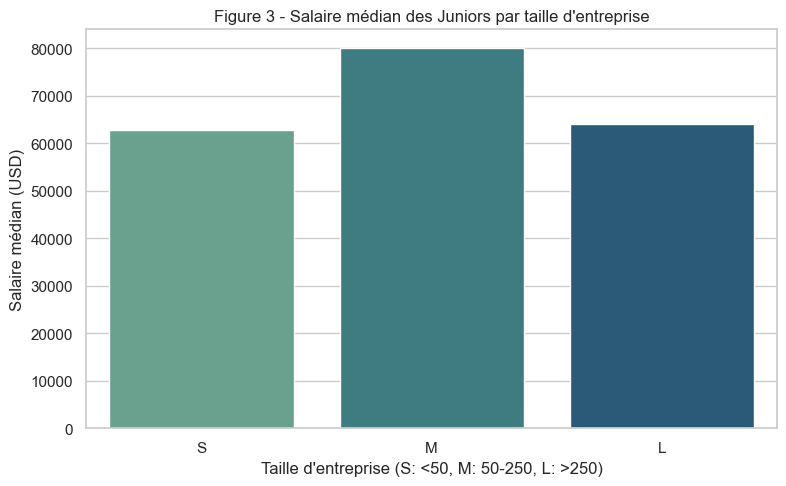

In [4]:
df_juniors = df[df["experience_level_fr"] == "Junior"]
print(
    df_juniors.groupby("company_size")["salary_in_usd"]
    .agg(["count", "median", "mean"])
    .round(0)
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=df_juniors,
    x="company_size",
    y="salary_in_usd",
    order=["S", "M", "L"],
    estimator="median",
    errorbar=None,
    palette="crest",
)
plt.title("Figure 3 - Salaire médian des Juniors par taille d'entreprise")
plt.xlabel("Taille d'entreprise (S: <50, M: 50-250, L: >250)")
plt.ylabel("Salaire médian (USD)")
plt.tight_layout()

plt.savefig(os.path.join(path_figures, "fig3_taille_entreprise_juniors.png"))
plt.show()

**Conclusion Question 3 :**  
Les moyennes et grandes entreprises (M et L) rémunèrent sensiblement mieux les profils juniors que les petites structures (S), avec un écart médian supérieur à 25 %.

## Question 4 : Évolution annuelle des rémunérations

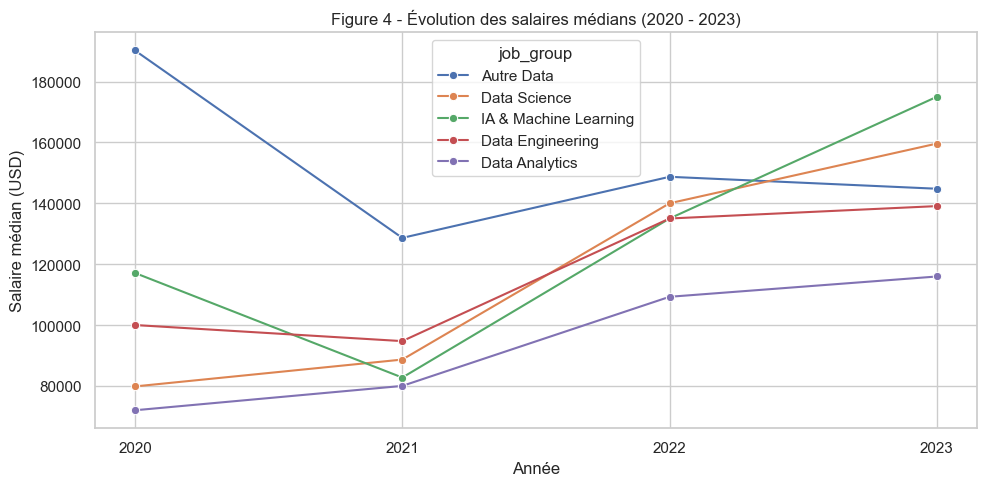

In [5]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=df,
    x="work_year",
    y="salary_in_usd",
    hue="job_group",
    estimator="median",
    errorbar=None,
    marker="o",
)
plt.title("Figure 4 - Évolution des salaires médians (2020 - 2023)")
plt.xlabel("Année")
plt.ylabel("Salaire médian (USD)")
plt.xticks(sorted(df["work_year"].unique()))
plt.tight_layout()

plt.savefig(os.path.join(path_figures, "fig4_evolution_temporelle.png"))
plt.show()

**Conclusion Question 4 :**  
La tendance globale montre une hausse constante des salaires médians entre 2020 et 2023, avec une accélération marquée sur les métiers de l'ingénierie data et du Machine Learning.

## Question 5 : Rémunération selon les continents (Exploitation de la jointure)

/var/folders/8_/0gftngvx6hv1b_1p1qtpmt240000gn/T/ipykernel_14831/384055972.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


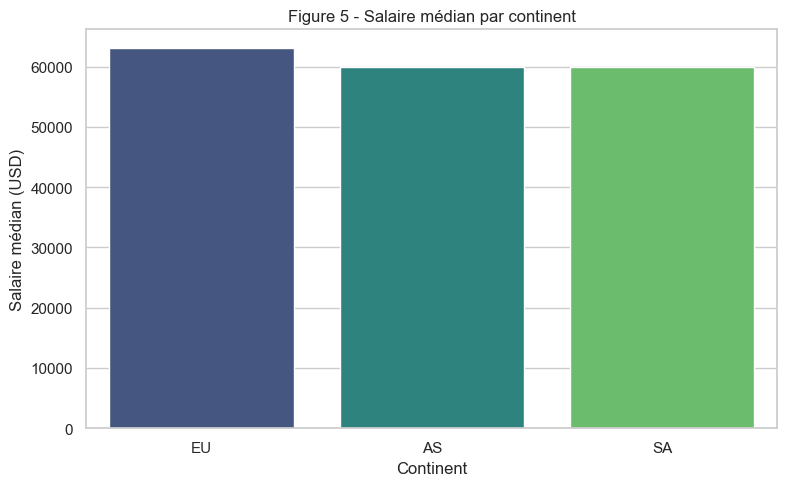

In [6]:
top_continents = df["Continent"].value_counts().head(3).index
df_geo_filtered = df[df["Continent"].isin(top_continents)]

plt.figure(figsize=(8, 5))
sns.barplot(
    data=df_geo_filtered,
    x="Continent",
    y="salary_in_usd",
    estimator="median",
    errorbar=None,
    palette="viridis",
)
plt.title("Figure 5 - Salaire médian par continent")
plt.xlabel("Continent")
plt.ylabel("Salaire médian (USD)")
plt.tight_layout()

plt.savefig(os.path.join(path_figures, "fig5_salaires_par_continent.png"))
plt.show()

**Conclusion Question 5 :**  
L'Amérique du Nord concentre les salaires médians les plus élevés du secteur, surpassant le marché européen de plus du double en valeur absolue brute.